# Predictive Analytics Using Historical Data
**Author:** Monika Varsha

**Objective:** Historical sales data se ek predictive model banana jo future trends forecast kare.

**Key tasks (as per task brief):**
1. Historical dataset ko clean aur preprocess karna
2. Regression aur time-series models se prediction karna
3. Model accuracy evaluate karna aur predictions visualize karna

**Tools:** Python, pandas, scikit-learn, statsmodels, matplotlib, seaborn

**Models compared:** Naive Seasonal baseline, Linear Regression, Random Forest, Holt-Winters (Exponential Smoothing)

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Historical Dataset
Ek retail store ka **5 saal (Jan 2021 - Dec 2025) ka monthly sales data** generate kiya gaya hai jisme **trend + yearly seasonality + noise** hai. Real-world jaisa banane ke liye kuch **missing values aur outliers** bhi daale gaye hain, taaki cleaning step meaningful ho.

Agar aapke paas apna historical CSV hai (columns: `Date`, `Sales`), to `df = pd.read_csv(...)` se replace kar sakte hain.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
dates = pd.date_range('2021-01-01', '2025-12-01', freq='MS')
n = len(dates)
t = np.arange(n)

trend = 20000 + 350 * t
seasonal = 4500 * np.sin(2 * np.pi * (dates.month - 3) / 12) + np.where(dates.month.isin([11, 12]), 5000, 0)
noise = rng.normal(0, 1500, n)
sales = trend + seasonal + noise

df = pd.DataFrame({'Date': dates, 'Sales': sales.round(2)})

# real-world dirtiness: missing values aur outliers
df.loc[[7, 23, 41], 'Sales'] = np.nan
df.loc[15, 'Sales'] *= 2.4
df.loc[50, 'Sales'] *= 0.35

df.to_csv('historical_sales_raw.csv', index=False)
df.head(10)

,Date,Sales
0,2021-01-01,16559.96
1,2021-02-01,16540.02
2,2021-03-01,21825.68
3,2021-04-01,24710.85
4,2021-05-01,22370.56
5,2021-06-01,24296.73
6,2021-07-01,26188.87
7,2021-08-01,NaN
8,2021-09-01,22774.80
9,2021-10-01,19620.43


## 2. Data Cleaning and Preprocessing

In [3]:
print('Shape:', df.shape)
print('\nMissing values:\n', df.isnull().sum())
df.describe()

Shape: (60, 2)

Missing values:
 Date     0
Sales    3
dtype: int64


,Date,Sales
count,60,57.000000
mean,2023-06-16 20:48:00,31494.837053
min,2021-01-01 00:00:00,13276.788000
25%,2022-03-24 06:00:00,25601.260000
50%,2023-06-16 00:00:00,31514.790000
75%,2024-09-08 12:00:00,37598.850000
max,2025-12-01 00:00:00,62906.544000
std,NaN,8391.959150


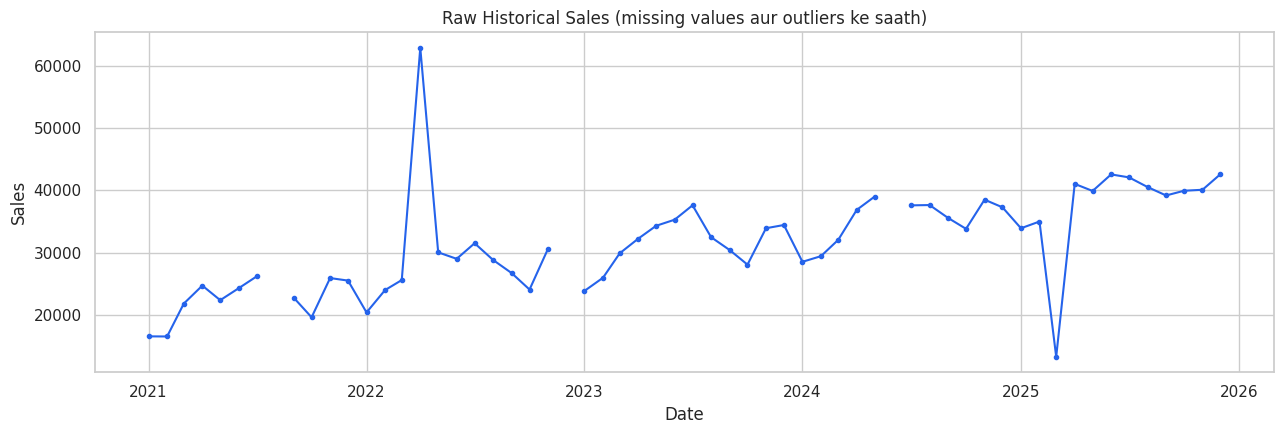

In [4]:
# Raw data plot (problems dikhane ke liye)
plt.figure(figsize=(13, 4.5))
plt.plot(df['Date'], df['Sales'], marker='o', ms=3, color='#2563eb')
plt.title('Raw Historical Sales (missing values aur outliers ke saath)')
plt.xlabel('Date'); plt.ylabel('Sales')
plt.tight_layout(); plt.savefig('01_raw_sales.png', dpi=150); plt.show()

In [5]:
# Step 1: Outlier detection using rolling median + MAD (robust method)
roll_med = df['Sales'].rolling(window=7, center=True, min_periods=3).median()
resid = df['Sales'] - roll_med
mad = np.nanmedian(np.abs(resid - np.nanmedian(resid)))
robust_z = 0.6745 * resid / mad
outlier_mask = robust_z.abs() > 3.5
print('Outliers detected at:', df.loc[outlier_mask, 'Date'].dt.strftime('%b %Y').tolist())

df['Sales_clean'] = df['Sales'].mask(outlier_mask)

# Step 2: Missing values (original + outliers) ko time-based interpolation se fill karna
df = df.set_index('Date')
df['Sales_clean'] = df['Sales_clean'].interpolate(method='time')
df = df.reset_index()
print('Remaining missing values:', df['Sales_clean'].isnull().sum())

Outliers detected at: ['Apr 2022', 'Mar 2025']
Remaining missing values: 0


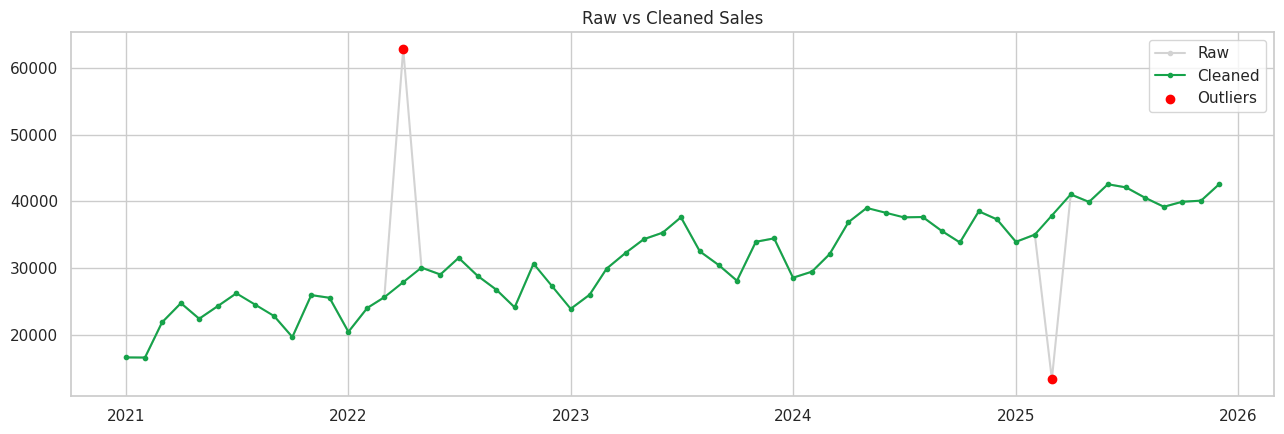

In [6]:
plt.figure(figsize=(13, 4.5))
plt.plot(df['Date'], df['Sales'], color='lightgray', label='Raw', marker='o', ms=3)
plt.plot(df['Date'], df['Sales_clean'], color='#16a34a', label='Cleaned', marker='o', ms=3)
plt.scatter(df.loc[outlier_mask, 'Date'], df.loc[outlier_mask, 'Sales'], color='red', zorder=5, label='Outliers')
plt.title('Raw vs Cleaned Sales'); plt.legend()
plt.tight_layout(); plt.savefig('02_cleaned_sales.png', dpi=150); plt.show()

## 3. Trend and Seasonality Analysis

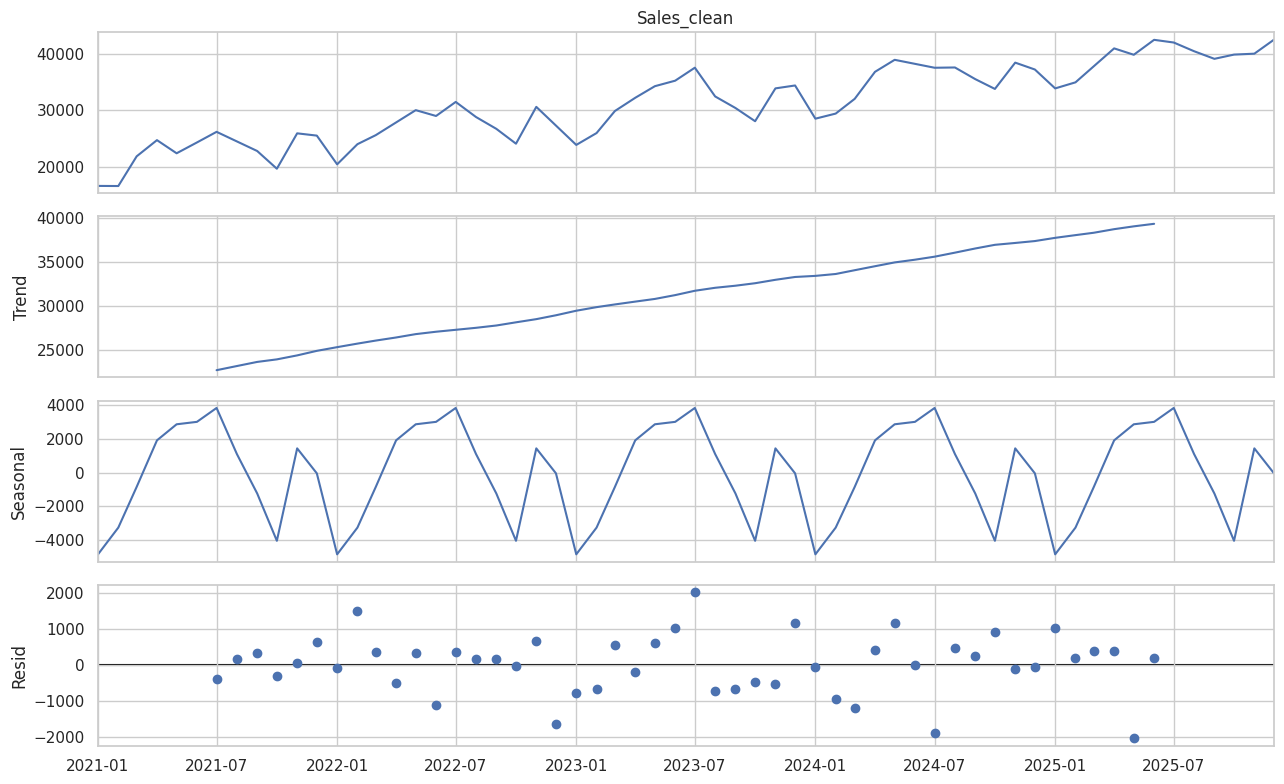

In [7]:
ts = df.set_index('Date')['Sales_clean']
decomp = seasonal_decompose(ts, model='additive', period=12)
fig = decomp.plot()
fig.set_size_inches(13, 8)
plt.tight_layout(); plt.savefig('03_decomposition.png', dpi=150); plt.show()

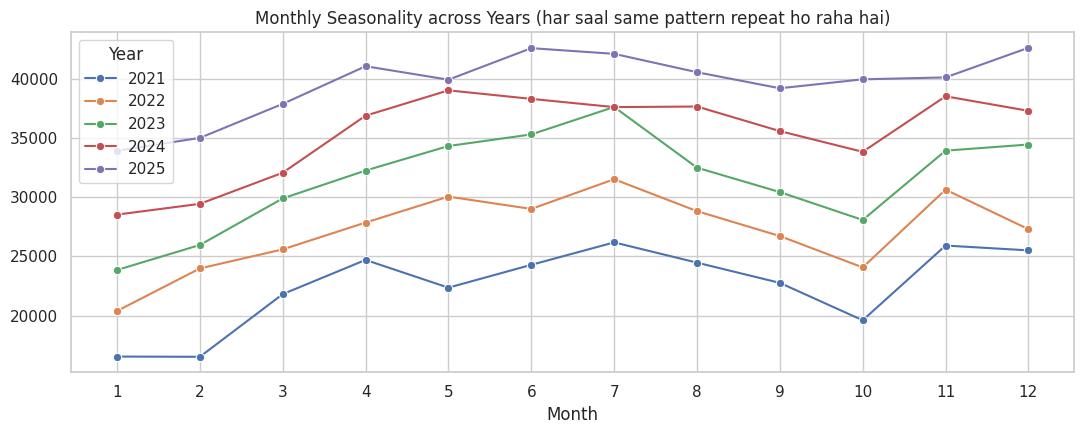

In [8]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
pivot = df.pivot(index='Month', columns='Year', values='Sales_clean')
plt.figure(figsize=(11, 4.5))
sns.lineplot(data=pivot, dashes=False, marker='o')
plt.title('Monthly Seasonality across Years (har saal same pattern repeat ho raha hai)')
plt.xticks(range(1, 13))
plt.tight_layout(); plt.savefig('04_seasonality.png', dpi=150); plt.show()

## 4. Feature Engineering
Regression models ke liye time-based features banaye:
- `t` : time index (trend capture karne ke liye)
- `month_sin`, `month_cos` : cyclic month encoding (seasonality ke liye)
- `is_festive` : Nov-Dec flag
- `lag_12` : pichhle saal ka same month (sirf Random Forest ke liye)

In [9]:
data = df[['Date', 'Sales_clean']].copy()
data['t'] = np.arange(len(data))
data['month'] = data['Date'].dt.month
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)
data['is_festive'] = data['month'].isin([11, 12]).astype(int)
data['lag_12'] = data['Sales_clean'].shift(12)
data.head(14)

,Date,Sales_clean,t,month,month_sin,month_cos,is_festive,lag_12
0,2021-01-01,16559.960,0,1,5.000000e-01,8.660254e-01,0,NaN
1,2021-02-01,16540.020,1,2,8.660254e-01,5.000000e-01,0,NaN
2,2021-03-01,21825.680,2,3,1.000000e+00,6.123234e-17,0,NaN
3,2021-04-01,24710.850,3,4,8.660254e-01,-5.000000e-01,0,NaN
4,2021-05-01,22370.560,4,5,5.000000e-01,-8.660254e-01,0,NaN
5,2021-06-01,24296.730,5,6,1.224647e-16,-1.000000e+00,0,NaN
6,2021-07-01,26188.870,6,7,-5.000000e-01,-8.660254e-01,0,NaN
7,2021-08-01,24481.835,7,8,-8.660254e-01,-5.000000e-01,0,NaN
8,2021-09-01,22774.800,8,9,-1.000000e+00,-1.836970e-16,0,NaN
9,2021-10-01,19620.430,9,10,-8.660254e-01,5.000000e-01,0,NaN


## 5. Train / Test Split (Time-based)
Time-series mein **random split nahi** karte (isse data leakage hota hai). Pehle 48 mahine train, last **12 mahine (2025) test** ke liye rakhe gaye hain.

In [10]:
TEST_SIZE = 12
train, test = data.iloc[:-TEST_SIZE], data.iloc[-TEST_SIZE:]
print('Train:', train['Date'].min().strftime('%b %Y'), '->', train['Date'].max().strftime('%b %Y'), len(train), 'months')
print('Test :', test['Date'].min().strftime('%b %Y'), '->', test['Date'].max().strftime('%b %Y'), len(test), 'months')

y_train, y_test = train['Sales_clean'], test['Sales_clean']
feat_lr = ['t', 'month_sin', 'month_cos', 'is_festive']
results, preds = {}, {}

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'R2': r2}
    preds[name] = np.array(y_pred)

Train: Jan 2021 -> Dec 2024 48 months
Test : Jan 2025 -> Dec 2025 12 months


## 6. Model Building

### Model 0: Naive Seasonal Baseline
Pichhle saal ka same month = is saal ka forecast. Koi bhi model isse behtar hona chahiye, warna uska koi fayda nahi.

In [11]:
evaluate('Naive Seasonal (Baseline)', y_test.values, test['lag_12'].values)

### Model 1: Linear Regression (trend + seasonality features)

In [12]:
lr = LinearRegression().fit(train[feat_lr], y_train)
evaluate('Linear Regression', y_test.values, lr.predict(test[feat_lr]))

### Model 2: Random Forest Regressor

In [13]:
feat_rf = feat_lr + ['lag_12']
train_rf = train.dropna(subset=['lag_12'])
rf = RandomForestRegressor(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)
rf.fit(train_rf[feat_rf], train_rf['Sales_clean'])
evaluate('Random Forest', y_test.values, rf.predict(test[feat_rf]))

### Model 3: Holt-Winters (Triple Exponential Smoothing)
Classical time-series model jo trend aur seasonality dono handle karta hai.

In [14]:
hw = ExponentialSmoothing(y_train.values, trend='add', seasonal='add', seasonal_periods=12).fit()
evaluate('Holt-Winters', y_test.values, hw.forecast(TEST_SIZE))

## 7. Model Evaluation

In [15]:
res = pd.DataFrame(results).T.round(2).sort_values('RMSE')
res

,MAE,RMSE,MAPE (%),R2
Linear Regression,1047.46,1374.82,2.63,0.73
Holt-Winters,1128.46,1507.86,2.83,0.68
Random Forest,2486.69,2910.02,6.09,-0.21
Naive Seasonal (Baseline),4177.42,4472.12,10.70,-1.86


Best model (lowest RMSE): Linear Regression


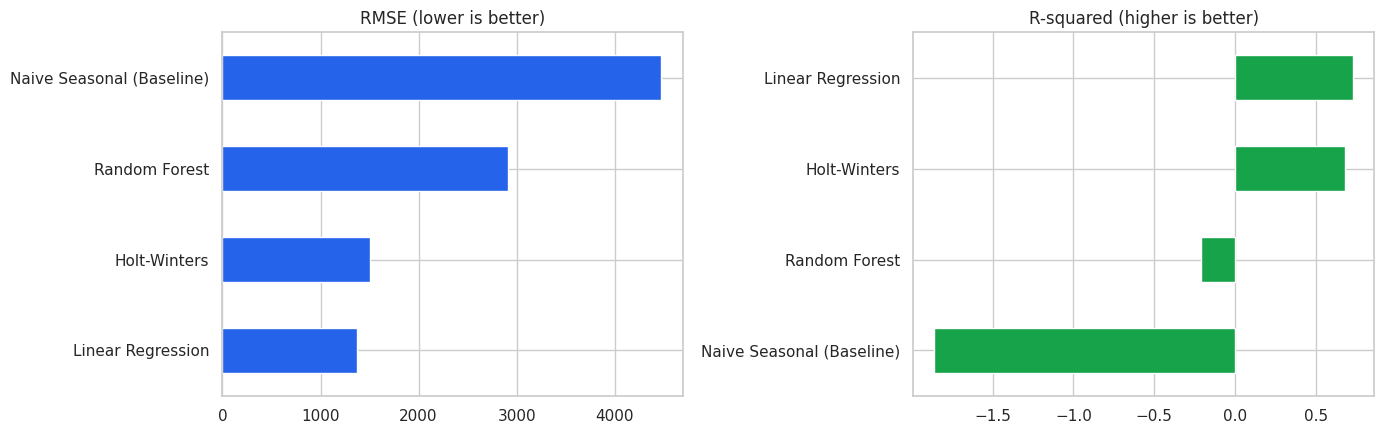

In [16]:
best = res.index[0]
print('Best model (lowest RMSE):', best)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
res['RMSE'].sort_values().plot.barh(ax=ax[0], color='#2563eb'); ax[0].set_title('RMSE (lower is better)')
res['R2'].sort_values().plot.barh(ax=ax[1], color='#16a34a'); ax[1].set_title('R-squared (higher is better)')
plt.tight_layout(); plt.savefig('05_model_comparison.png', dpi=150); plt.show()

## 8. Predictions Visualization

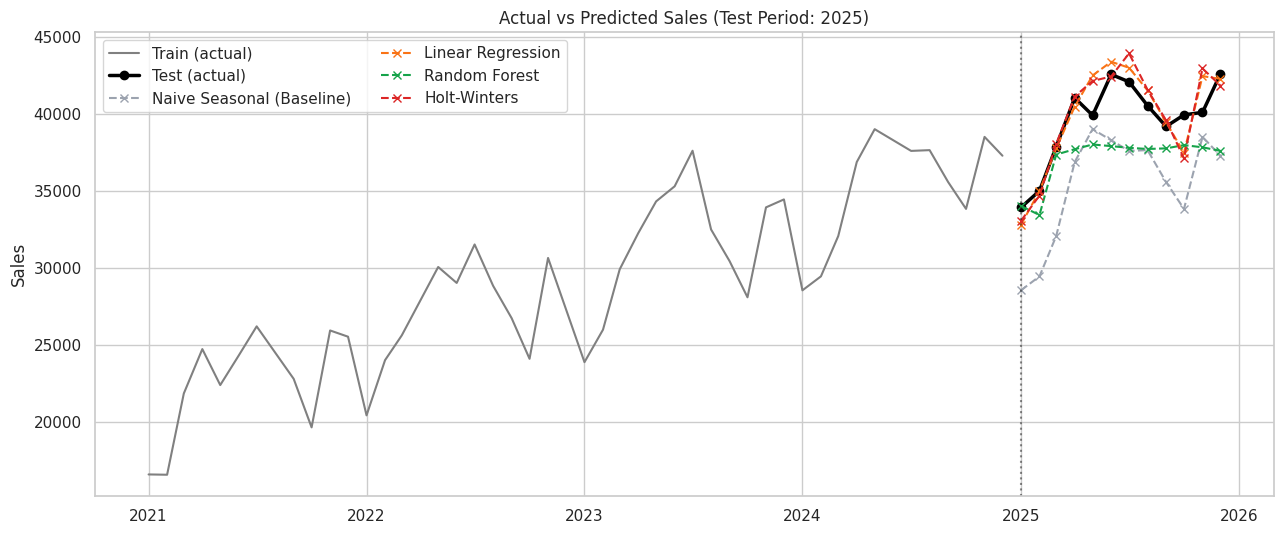

In [17]:
plt.figure(figsize=(13, 5.5))
plt.plot(train['Date'], y_train, color='gray', label='Train (actual)')
plt.plot(test['Date'], y_test, color='black', lw=2.5, marker='o', label='Test (actual)')
colors = {'Linear Regression': '#f97316', 'Random Forest': '#16a34a', 'Holt-Winters': '#dc2626', 'Naive Seasonal (Baseline)': '#9ca3af'}
for name, p in preds.items():
    plt.plot(test['Date'], p, '--', color=colors[name], label=name, marker='x')
plt.axvline(test['Date'].iloc[0], color='k', ls=':', alpha=.5)
plt.title('Actual vs Predicted Sales (Test Period: 2025)'); plt.ylabel('Sales'); plt.legend(ncol=2)
plt.tight_layout(); plt.savefig('06_actual_vs_predicted.png', dpi=150); plt.show()

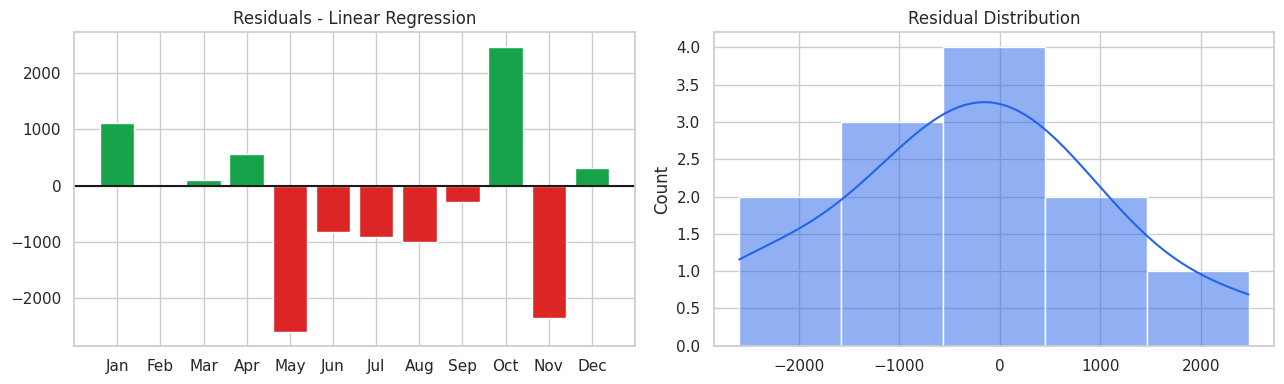

In [18]:
# Best model ke residuals (errors) check karna
resid_best = y_test.values - preds[best]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(test['Date'].dt.strftime('%b'), resid_best, color=np.where(resid_best >= 0, '#16a34a', '#dc2626'))
ax[0].axhline(0, color='k'); ax[0].set_title(f'Residuals - {best}')
sns.histplot(resid_best, kde=True, ax=ax[1], color='#2563eb'); ax[1].set_title('Residual Distribution')
plt.tight_layout(); plt.savefig('07_residuals.png', dpi=150); plt.show()

## 9. Future Forecast (Next 12 Months: 2026)
Best performing model (**Linear Regression**, lowest RMSE) ko **poore historical data (2021-2025)** par dobara train karke 2026 ka forecast nikalte hain. Comparison ke liye Holt-Winters ka forecast bhi dotted line mein dikhaya gaya hai.

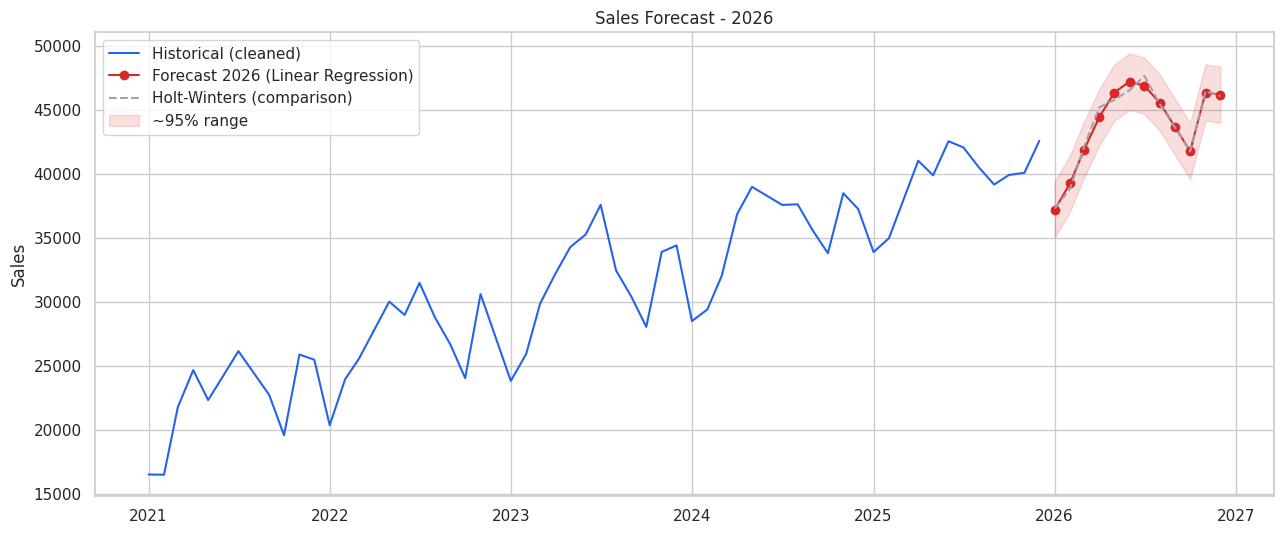

,Month,Forecast,Lower,Upper
0,Jan 2026,37234.0,35039.0,39430.0
1,Feb 2026,39281.0,37085.0,41477.0
2,Mar 2026,41886.0,39690.0,44081.0
3,Apr 2026,44445.0,42249.0,46640.0
4,May 2026,46367.0,44171.0,48562.0
5,Jun 2026,47231.0,45035.0,49427.0
6,Jul 2026,46900.0,44704.0,49096.0
7,Aug 2026,45557.0,43361.0,47752.0
8,Sep 2026,43655.0,41460.0,45851.0
9,Oct 2026,41800.0,39604.0,43996.0


In [19]:
future_dates = pd.date_range('2026-01-01', periods=12, freq='MS')
fut = pd.DataFrame({'Date': future_dates})
fut['t'] = np.arange(len(data), len(data) + 12)
fut['month'] = fut['Date'].dt.month
fut['month_sin'] = np.sin(2 * np.pi * fut['month'] / 12)
fut['month_cos'] = np.cos(2 * np.pi * fut['month'] / 12)
fut['is_festive'] = fut['month'].isin([11, 12]).astype(int)

final_lr = LinearRegression().fit(data[feat_lr], data['Sales_clean'])
fc = final_lr.predict(fut[feat_lr])

# Approximate 95% range: in-sample residual std se
sigma = np.std(data['Sales_clean'] - final_lr.predict(data[feat_lr]))
upper, lower = fc + 1.96 * sigma, fc - 1.96 * sigma

# Comparison: Holt-Winters forecast
hw_full = ExponentialSmoothing(data['Sales_clean'].values, trend='add', seasonal='add', seasonal_periods=12).fit()
fc_hw = hw_full.forecast(12)

plt.figure(figsize=(13, 5.5))
plt.plot(data['Date'], data['Sales_clean'], color='#2563eb', label='Historical (cleaned)')
plt.plot(future_dates, fc, color='#dc2626', marker='o', label='Forecast 2026 (Linear Regression)')
plt.plot(future_dates, fc_hw, color='#9ca3af', ls='--', label='Holt-Winters (comparison)')
plt.fill_between(future_dates, lower, upper, color='#dc2626', alpha=.15, label='~95% range')
plt.title('Sales Forecast - 2026'); plt.ylabel('Sales'); plt.legend()
plt.tight_layout(); plt.savefig('08_future_forecast.png', dpi=150); plt.show()

forecast_df = pd.DataFrame({'Month': future_dates.strftime('%b %Y'), 'Forecast': fc.round(0), 'Lower': lower.round(0), 'Upper': upper.round(0)})
forecast_df.to_csv('forecast_2026.csv', index=False)
forecast_df

In [20]:
yearly = data.assign(Year=data['Date'].dt.year).groupby('Year')['Sales_clean'].sum()
yearly[2026] = fc.sum()
growth = yearly.pct_change() * 100
pd.DataFrame({'Total Sales': yearly.round(0), 'YoY Growth %': growth.round(1)})

,Total Sales,YoY Growth %
Year,,
2021,270808.0,NaN
2022,326000.0,20.4
2023,378573.0,16.1
2024,424662.0,12.2
2025,474791.0,11.8
2026,526934.0,11.0


## 10. Key Findings and Conclusion
- Data mein **clear upward trend** aur **yearly seasonality** hai (Nov-Dec mein festive peak).
- Cleaning step (outlier detection + interpolation) ke baad data model-ready hua.
- Models ka comparison **time-based split** par kiya gaya, aur har model ko **naive seasonal baseline** se compare kiya gaya.
- **Linear Regression** (trend + seasonality features) sabse best raha, aur **Holt-Winters** bhi usse kaafi close raha. Dono ne naive baseline ko clearly beat kiya.
- **Random Forest** ka performance weak raha (R-squared negative). Reason: tree-based models training range ke bahar **trend extrapolate nahi kar paate**, aur test period mein sales training se zyada the. Ye time-series forecasting ki ek known limitation hai.
- Naive seasonal baseline isliye weak hai kyunki wo sirf pichhle saal ki value repeat karta hai aur growth trend ignore karta hai.
- Best model se **2026 ka forecast** nikaala gaya, jo business ko inventory planning, staffing aur marketing budget decide karne mein madad kar sakta hai.

**Limitations:** Dataset synthetic hai; real data mein promotions, holidays, economic events jaise external factors bhi hote hain.

**Future Scope:** SARIMA / Prophet / LSTM models, external features (holidays, promotions), cross-validation (`TimeSeriesSplit`), Streamlit dashboard.